# 07 — Évaluation finale, seuil de décision et robustesse

**Objectifs**
1. Choisir le **seuil de décision** qui minimise le **coût métier** (et non le seuil arbitraire de 0,5), puis étudier sa **sensibilité** au coût supposé d'une fausse alerte ;
2. Réaliser l'**évaluation finale, unique, sur le jeu de test** (jours 15-16), jamais utilisé jusqu'ici ;
3. Conclure sur l'hypothèse **H6** : un modèle de Machine Learning surpasse-t-il significativement la règle métier `isFlaggedFraud` ?
4. Mesurer la **robustesse temporelle** sur le jeu de **drift** (jours 17-30), dont le régime est très différent (volume faible, taux de fraude 14 fois plus élevé que sur le test).

**Règle d'or** : tous les choix (seuils, modèles) sont **figés sur la validation** avant de toucher au test. Le test n'est évalué qu'**une seule fois** ; aucun réglage n'est modifié après avoir vu ses résultats.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

from src.config import TARGET, MODELS_DIR, COST_FALSE_POSITIVE
from src.split import load_split, step_to_day
from src.baselines import RegleIsFlagged, RegleCompteVide, make_logistic_regression
from src.evaluate import (compare_models, cost_curve, optimal_threshold, bootstrap_pr_auc,
                          plot_pr_curves, save_results, MODEL_COLORS)
from src.viz import set_style, save_fig, TEXT_SECONDARY

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

train = load_split("train")
data = {name: load_split(name) for name in ["val", "test", "drift"]}
for name, df in data.items():
    print(f"{name:<6}: {len(df):>8,} transactions, {df[TARGET].sum():>5,} fraudes "
          f"({df[TARGET].mean():.3%}), montant fraudé {df.loc[df[TARGET] == 1, 'amount'].sum() / 1e6:,.0f} M")
print(f"Coût d'une fausse alerte (hypothèse de référence) : {COST_FALSE_POSITIVE:,}")

val   :  346,348 transactions,   498 fraudes (0.144%), montant fraudé 695 M
test  :  349,818 transactions,   570 fraudes (0.163%), montant fraudé 968 M
drift :  156,659 transactions, 3,634 fraudes (2.320%), montant fraudé 5,609 M
Coût d'une fausse alerte (hypothèse de référence) : 5,000


## 0. Les modèles comparés

| Modèle | Jeu de variables | Origine |
|---|---|---|
| Règle `isFlaggedFraud` | — | règle métier existante (H6) |
| Règle « compte vidé » | soldes | notebook 05 |
| Logistique | `complet` / `transaction` | notebook 05 |
| **LightGBM** | `complet` / `transaction` | notebook 06 (modèles retenus) |

Les modèles appris sont ceux **entraînés sur le train** aux notebooks 05 et 06 (la logistique `transaction`, rapide, est réentraînée à l'identique).

In [2]:
models = {
    "Règle isFlaggedFraud": RegleIsFlagged().fit(train),
    "Règle compte vidé": RegleCompteVide().fit(train),
    "Logistique (complet)": joblib.load(MODELS_DIR / "baseline_logistique_complet.joblib"),
    "LightGBM (complet)": joblib.load(MODELS_DIR / "lightgbm_complet.joblib"),
    "Logistique (transaction)": make_logistic_regression("transaction").fit(train, train[TARGET]),
    "LightGBM (transaction)": joblib.load(MODELS_DIR / "lightgbm_transaction.joblib"),
}
RULES = ["Règle isFlaggedFraud", "Règle compte vidé"]
LEARNED = [m for m in models if m not in RULES]

scores = {split: {name: model.predict_proba(df)[:, 1] for name, model in models.items()}
          for split, df in data.items()}
y = {split: df[TARGET].to_numpy() for split, df in data.items()}
amounts = {split: df["amount"].to_numpy() for split, df in data.items()}
del train

## 1. Choix du seuil par minimisation du coût métier (validation)

Le coût d'un ensemble de décisions est (notebook 05) :

$$\text{Coût} = \underbrace{\sum_{\text{fraudes ratées}} \text{montant}}_{\text{pertes}} \; + \; n_{\text{fausses alertes}} \times C_{FP}, \qquad C_{FP} = 5\,000$$

Baisser le seuil fait attraper plus de fraudes (moins de pertes) mais déclenche plus de fausses alertes. Le seuil optimal réalise le meilleur compromis. Il est calculé **sur la validation** pour chaque modèle appris ; les règles, binaires, n'ont pas de seuil à régler.

In [3]:
curves = {name: cost_curve(y["val"], scores["val"][name], amounts["val"]) for name in LEARNED}
thresholds = {name: optimal_threshold(y["val"], scores["val"][name], amounts["val"]) for name in LEARNED}
no_model_cost = amounts["val"][y["val"] == 1].sum()

rows = []
for name in LEARNED:
    c = curves[name]
    at_05 = c[c["seuil"] >= 0.5].iloc[-1]
    best = c.loc[c["cout_total"].idxmin()]
    rows.append({"modele": name, "seuil_optimal": best["seuil"],
                 "alertes_0.5": at_05["n_alertes"], "cout_0.5_M": at_05["cout_total"] / 1e6,
                 "alertes_opt": best["n_alertes"], "rappel_opt": best["rappel"],
                 "precision_opt": best["precision"], "cout_opt_M": best["cout_total"] / 1e6})
seuils = pd.DataFrame(rows).set_index("modele")
_ = save_results(seuils, "07_seuils_validation")
print(f"Coût sans aucun modèle (toutes les fraudes passent) : {no_model_cost / 1e6:,.0f} M")
seuils

Coût sans aucun modèle (toutes les fraudes passent) : 695 M


,seuil_optimal,alertes_0.5,cout_0.5_M,alertes_opt,rappel_opt,precision_opt,cout_opt_M
modele,,,,,,,
Logistique (complet),0.9726,556.0000,0.2900,499.0000,1.0000,0.9980,0.0050
LightGBM (complet),0.9999,499.0000,0.0050,498.0000,1.0000,1.0000,0.0000
Logistique (transaction),0.7099,"71,593.0000",461.4538,"26,723.0000",0.4880,0.0091,367.0571
LightGBM (transaction),0.8431,"47,140.0000",274.8019,"8,985.0000",0.5341,0.0296,133.0823


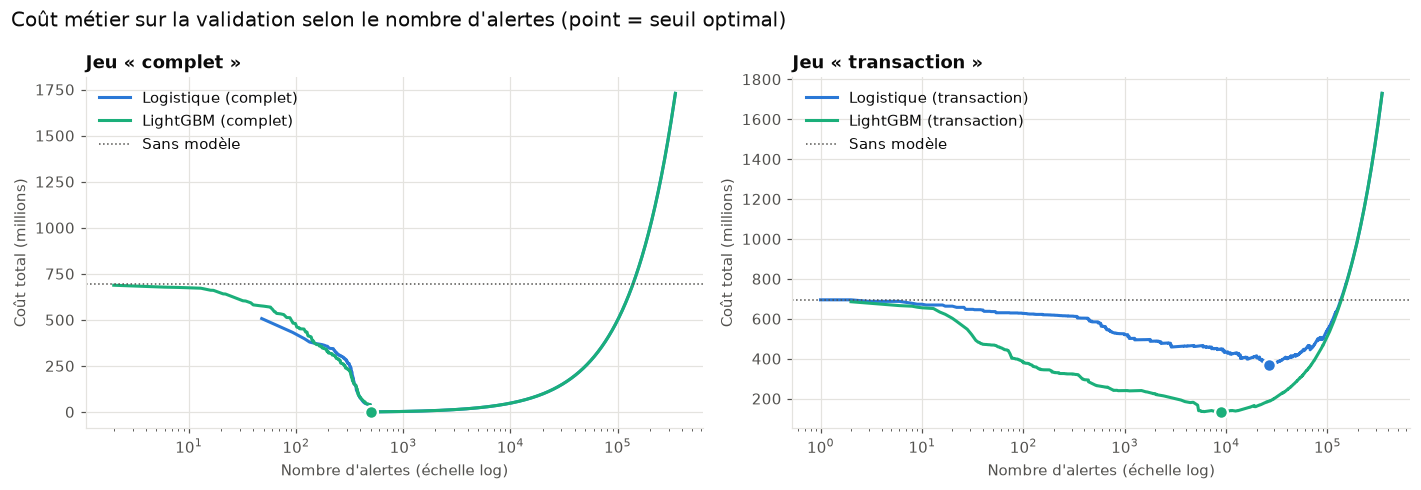

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for ax, fs in zip(axes, ["complet", "transaction"]):
    for color, kind in zip(MODEL_COLORS, ["Logistique", "LightGBM"]):
        name = f"{kind} ({fs})"
        c = curves[name].iloc[1:]
        ax.plot(c["n_alertes"], c["cout_total"] / 1e6, color=color, linewidth=2, label=name)
        best = c.loc[c["cout_total"].idxmin()]
        ax.scatter(best["n_alertes"], best["cout_total"] / 1e6, s=70, color=color, zorder=3,
                   edgecolor="white", linewidth=1.5)
    ax.axhline(no_model_cost / 1e6, color=TEXT_SECONDARY, linestyle=":", linewidth=1,
               label="Sans modèle")
    ax.set_xscale("log")
    ax.set_xlabel("Nombre d'alertes (échelle log)")
    ax.set_ylabel("Coût total (millions)")
    ax.set_title(f"Jeu « {fs} »", loc="left")
    ax.legend(loc="upper left")
fig.suptitle("Coût métier sur la validation selon le nombre d'alertes (point = seuil optimal)",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "07_cout_seuil")
plt.show()

**Lecture**
- **Jeu `complet`** : le seuil optimal est très élevé (0,97 pour la logistique, 0,9999 pour LightGBM). Le modèle sépare si bien les classes qu'on peut exiger une quasi-certitude sans rater de fraude. LightGBM détecte alors les 498 fraudes avec **aucune** fausse alerte : coût nul.
- **Jeu `transaction`** : pour LightGBM, le seuil optimal (0,84) ramène le nombre d'alertes de 47 140 (seuil 0,5) à **8 985**, et **divise le coût par deux** (275 M → 133 M). Par rapport à l'absence de modèle (695 M de fraudes non détectées), le coût baisse de **81 %**.
- **Le seuil optimal tolère beaucoup de fausses alertes** : précision de 3 % seulement, soit une alerte justifiée sur 33. C'est rationnel : une fraude coûte en moyenne ~1,4 M, contre 5 000 par fausse alerte. Rater une seule fraude coûte autant que ~280 fausses alertes.
- Le modèle détecte **53 % des fraudes** mais **87 % du montant fraudé** : le critère de coût pousse à attraper en priorité les **grosses** fraudes.
- La logistique `transaction` reste très loin derrière (367 M au mieux) : le gain de LightGBM en PR-AUC (notebook 06) se traduit directement en euros économisés.

## 2. Sensibilité au coût d'une fausse alerte

Le coût d'une fausse alerte ($C_{FP}$ = 5 000) est une **hypothèse** : il dépend du coût d'une vérification manuelle, de la gêne pour le client, du risque qu'il quitte l'opérateur… On fait varier $C_{FP}$ de 100 à 100 000 et on recalcule le seuil optimal du modèle **LightGBM (transaction)**, le seul pour lequel le compromis est réellement difficile.

In [5]:
name = "LightGBM (transaction)"
rows = []
for c_fp in [100, 500, 1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000]:
    c = cost_curve(y["val"], scores["val"][name], amounts["val"], cost_fp=c_fp)
    best = c.loc[c["cout_total"].idxmin()]
    rows.append({"cout_fausse_alerte": c_fp, "seuil": best["seuil"], "n_alertes": best["n_alertes"],
                 "rappel": best["rappel"], "precision": best["precision"],
                 "montant_detecte_pct": 100 * (1 - best["cout_fraudes_ratees"] / no_model_cost),
                 "cout_total_M": best["cout_total"] / 1e6})
sensibilite = pd.DataFrame(rows).set_index("cout_fausse_alerte")
_ = save_results(sensibilite, "07_sensibilite_cout_alerte")
sensibilite

,seuil,n_alertes,rappel,precision,montant_detecte_pct,cout_total_M
cout_fausse_alerte,,,,,,
100,0.2583,"110,199.0000",0.8735,0.0039,98.3491,22.4463
500,0.4328,"66,545.0000",0.7811,0.0058,96.2556,59.0936
1000,0.6453,"27,369.0000",0.6667,0.0121,92.2989,80.5430
2000,0.8008,"13,073.0000",0.5643,0.0215,89.1618,100.8860
5000,0.8431,"8,985.0000",0.5341,0.0296,87.1201,133.0823
10000,0.8928,"5,702.0000",0.5000,0.0437,84.4472,162.5881
20000,0.8973,"5,364.0000",0.4960,0.0460,83.6723,215.7815
50000,0.9476,778.0000,0.4177,0.2674,65.7132,266.7186
100000,0.9476,778.0000,0.4177,0.2674,65.7132,295.2186


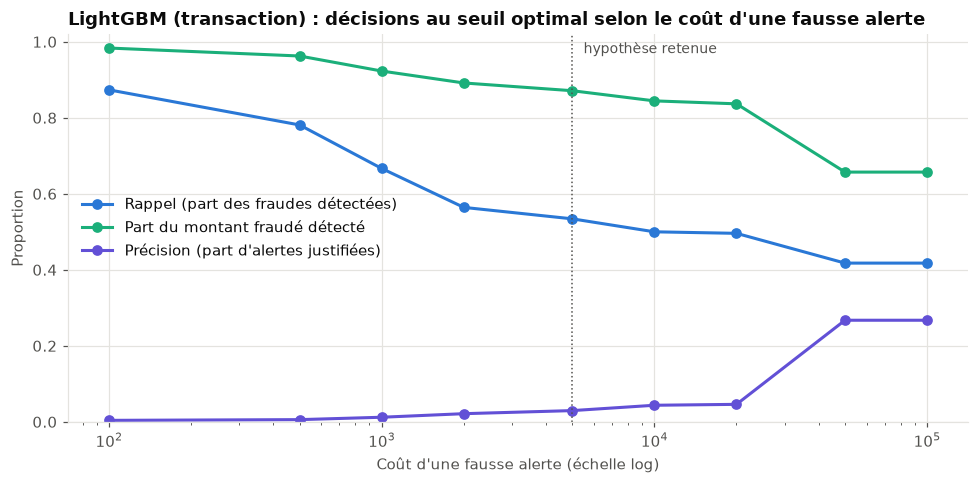

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sensibilite.index, sensibilite["rappel"], marker="o", color=MODEL_COLORS[0], linewidth=2,
        label="Rappel (part des fraudes détectées)")
ax.plot(sensibilite.index, sensibilite["montant_detecte_pct"] / 100, marker="o", color=MODEL_COLORS[1],
        linewidth=2, label="Part du montant fraudé détecté")
ax.plot(sensibilite.index, sensibilite["precision"], marker="o", color=MODEL_COLORS[2], linewidth=2,
        label="Précision (part d'alertes justifiées)")
ax.axvline(COST_FALSE_POSITIVE, color=TEXT_SECONDARY, linestyle=":", linewidth=1)
ax.text(COST_FALSE_POSITIVE * 1.1, 0.97, "hypothèse retenue", color=TEXT_SECONDARY, fontsize=9)
ax.set_xscale("log")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Coût d'une fausse alerte (échelle log)")
ax.set_ylabel("Proportion")
ax.set_title("LightGBM (transaction) : décisions au seuil optimal selon le coût d'une fausse alerte",
             loc="left")
ax.legend(loc="center left")
fig.tight_layout()
save_fig(fig, "07_sensibilite_cout_alerte")
plt.show()

**Lecture**
- **Le seuil s'adapte logiquement au coût d'une fausse alerte** : si une vérification coûte 100, on alerte sur 110 000 transactions et on intercepte 98 % du montant fraudé ; si elle coûte 50 000, on se limite à 778 alertes (précision 27 %), et on n'intercepte plus que 66 % du montant.
- **La décision est stable autour de l'hypothèse retenue** : quand $C_{FP}$ varie d'un facteur 10 (de 2 000 à 20 000), le rappel reste entre 50 et 56 % et le montant détecté entre 84 et 89 %. Le choix du seuil n'est donc pas fragile vis-à-vis d'une hypothèse de coût mal estimée.
- Au-delà de 50 000, plus rien ne change : il ne reste que le **noyau d'alertes très sûres** (≈ 40 % des fraudes), identifié au notebook 06 comme principalement **nocturne** (H5).
- ➡️ En pratique, $C_{FP}$ doit être fixé avec le métier (coût d'un analyste, gêne client). Le pipeline permet de recalculer le seuil en une ligne (`optimal_threshold`).

## 3. Évaluation finale sur le test (unique)

Les seuils sont **figés** (section 1). Le test (jours 15-16) est évalué **une seule fois**, avec les mêmes métriques que sur la validation. On compare aussi la PR-AUC validation → test pour vérifier que les performances **se généralisent** à des jours jamais vus.

In [7]:
test_thresholds = {**{r: 0.5 for r in RULES}, **thresholds}
test = compare_models(scores["test"], y["test"], thresholds=test_thresholds, amounts=amounts["test"])
test["pr_auc_val"] = pd.Series({n: average_precision_score(y["val"], s) for n, s in scores["val"].items()})
_ = save_results(test, "07_test")
test[["pr_auc_val", "pr_auc", "seuil", "precision", "rappel", "n_alertes", "fp", "fn",
      "montant_detecte_pct", "cout_total"]]

,pr_auc_val,pr_auc,seuil,precision,rappel,n_alertes,fp,fn,montant_detecte_pct,cout_total
Règle isFlaggedFraud,0.0014,0.0034,0.5000,1.0000,0.0018,1.0000,0.0000,569.0000,0.5054,"963,170,346.8400"
Règle compte vidé,0.9920,0.9720,0.5000,1.0000,0.9719,554.0000,0.0000,16.0000,84.5051,"150,000,000.0000"
Logistique (complet),1.0000,0.9998,0.9726,1.0000,0.9982,569.0000,0.0000,1.0000,100.0000,0.0000
LightGBM (complet),1.0000,1.0000,0.9999,1.0000,0.9982,569.0000,0.0000,1.0000,100.0000,0.0000
Logistique (transaction),0.0500,0.1101,0.7099,0.0129,0.5000,"22,073.0000","21,788.0000",285.0000,75.1681,"349,327,958.8200"
LightGBM (transaction),0.3754,0.4166,0.8431,0.0552,0.5404,"5,582.0000","5,274.0000",262.0000,88.1858,"140,738,482.3200"


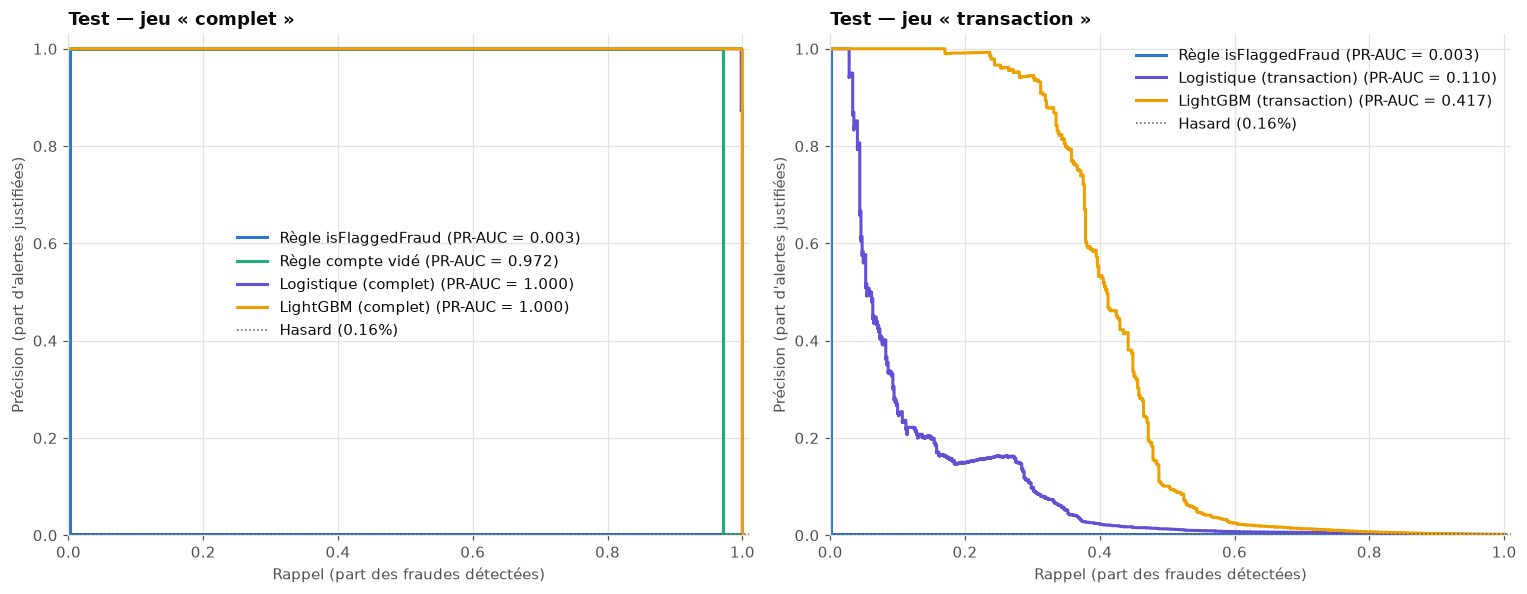

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
groups = {"complet": ["Règle isFlaggedFraud", "Règle compte vidé", "Logistique (complet)", "LightGBM (complet)"],
          "transaction": ["Règle isFlaggedFraud", "Logistique (transaction)", "LightGBM (transaction)"]}
# Une couleur fixe par modèle, identique dans les deux panneaux
color_of = {"Règle isFlaggedFraud": MODEL_COLORS[0], "Règle compte vidé": MODEL_COLORS[1],
            "Logistique": MODEL_COLORS[2], "LightGBM": MODEL_COLORS[3]}
for ax, (fs, names), loc in zip(axes, groups.items(), ["center", "upper right"]):
    colors = [color_of.get(n, color_of.get(n.split(" (")[0])) for n in names]
    plot_pr_curves(ax, {n: scores["test"][n] for n in names}, y["test"], legend_loc=loc, colors=colors)
    ax.set_title(f"Test — jeu « {fs} »", loc="left")
fig.tight_layout()
save_fig(fig, "07_test_courbes_pr")
plt.show()

**Lecture**
- **Les performances se généralisent** : sur le test, la PR-AUC est **égale ou supérieure** à celle de la validation pour les modèles appris (LightGBM `transaction` : 0,375 → **0,417** ; logistique `transaction` : 0,050 → 0,110). Aucun signe de sur-ajustement à la validation. La légère hausse s'explique en partie par un taux de fraude un peu plus élevé sur le test (0,163 % contre 0,144 %), qui relève mécaniquement la PR-AUC.
- **Jeu `complet`** : LightGBM et la logistique détectent **569 fraudes sur 570** sans aucune fausse alerte. La seule fraude manquée a un **montant nul** : coût total = 0. La règle « compte vidé » recule un peu (0,992 → 0,972) : elle rate 16 fraudes, dont 15 transferts plafonnés à 10 M depuis des comptes plus riches, soit **150 M** de pertes.
- **Jeu `transaction`** : au seuil choisi sur la validation, LightGBM lève **5 582 alertes** (précision 5,5 %), détecte 54 % des fraudes et **88 % du montant fraudé**. Le coût passe de 968 M sans modèle à **141 M** (−85 %).
- Le seuil choisi sur la validation se comporte sur le test comme prévu (rappel 54 % contre 53 % sur la validation) : il est bien **transposable** à des jours jamais vus.

### Test de l'hypothèse H6

**H6** : un modèle de Machine Learning surpasse significativement la règle métier `isFlaggedFraud`.

On compare la PR-AUC de chaque modèle à celle de la règle par **bootstrap apparié** sur le test (300 rééchantillonnages), et on compare les **coûts** au seuil retenu.

In [9]:
boot_test = bootstrap_pr_auc(y["test"], scores["test"], reference="Règle isFlaggedFraud", n_boot=300)
boot_test["cout_total_M"] = test["cout_total"] / 1e6
boot_test["economie_vs_regle_M"] = (test.loc["Règle isFlaggedFraud", "cout_total"] - test["cout_total"]) / 1e6
_ = save_results(boot_test, "07_bootstrap_test")
boot_test

,pr_auc,ic_bas,ic_haut,ecart_ref,ecart_ic_bas,ecart_ic_haut,p_meilleur,cout_total_M,economie_vs_regle_M
Règle isFlaggedFraud,0.0034,0.0015,0.0071,0.0000,0.0000,0.0000,0.0000,963.1703,0.0000
Règle compte vidé,0.9720,0.9595,0.9834,0.9686,0.9551,0.9805,1.0000,150.0000,813.1703
Logistique (complet),0.9998,0.9992,1.0000,0.9964,0.9926,0.9984,1.0000,0.0000,963.1703
LightGBM (complet),1.0000,1.0000,1.0000,0.9966,0.9929,0.9985,1.0000,0.0000,963.1703
Logistique (transaction),0.1101,0.0833,0.1346,0.1068,0.0803,0.1310,1.0000,349.3280,613.8424
LightGBM (transaction),0.4166,0.3724,0.4544,0.4132,0.3674,0.4510,1.0000,140.7385,822.4319


**Verdict sur H6 : hypothèse validée.**
- La règle `isFlaggedFraud` ne lève qu'**une seule alerte** sur le test (rappel 0,2 %) : elle laisse passer 963 M sur 968 M de fraudes.
- **Tous** les modèles appris la surpassent : l'intervalle de confiance à 95 % de l'écart de PR-AUC est entièrement positif, et le modèle fait mieux dans **100 %** des rééchantillonnages. Économies sur les 2 jours de test : **963 M** (LightGBM `complet`) et **822 M** (LightGBM `transaction`, sans aucune variable de solde).
- **Nuance** : la règle existante est si faible que la barre est basse. Même la règle simple « compte vidé » la bat largement. La comparaison la plus exigeante est donc celle avec cette règle : LightGBM `complet` la bat aussi (PR-AUC 0,972 → 1,000, pertes 150 M → 0).

## 4. Robustesse temporelle : le jeu de drift (jours 17-30)

Le jeu de drift appartient au **régime anormal** identifié au notebook 03 : peu de transactions, mais un taux de fraude 14 fois plus élevé que sur le test (2,3 % contre 0,16 %). C'est un **test de résistance** : les modèles et leurs seuils ont été choisis sur une période « normale ».

**Attention à la comparaison** : la PR-AUC dépend mécaniquement de la prévalence (un modèle aléatoire obtient une PR-AUC égale au taux de fraude). Avec un taux de fraude 14 fois plus élevé que sur le test, une PR-AUC stable cache en réalité une **dégradation**. Pour juger la robustesse, on s'appuie donc aussi sur la **ROC-AUC**, qui ne dépend pas de la prévalence (0,5 = hasard, 1 = parfait).

In [10]:
drift = compare_models(scores["drift"], y["drift"], thresholds=test_thresholds, amounts=amounts["drift"])
drift["pr_auc_test"] = test["pr_auc"]
drift["roc_auc_test"] = test["roc_auc"]
_ = save_results(drift, "07_drift")
drift[["pr_auc_test", "pr_auc", "roc_auc_test", "roc_auc", "precision", "rappel", "n_alertes",
       "montant_detecte_pct"]]

,pr_auc_test,pr_auc,roc_auc_test,roc_auc,precision,rappel,n_alertes,montant_detecte_pct
Règle isFlaggedFraud,0.0034,0.0264,0.5009,0.5017,1.0000,0.0033,12.0000,1.1777
Règle compte vidé,0.9720,0.9731,0.9860,0.9862,1.0000,0.9725,"3,534.0000",84.5375
Logistique (complet),0.9998,0.9996,1.0000,1.0000,1.0000,0.9948,"3,615.0000",98.9784
LightGBM (complet),1.0000,1.0000,1.0000,1.0000,1.0000,0.9948,"3,615.0000",99.1504
Logistique (transaction),0.1101,0.1974,0.8293,0.8140,0.1168,0.5055,"15,722.0000",69.9692
LightGBM (transaction),0.4166,0.4200,0.8803,0.8730,0.2670,0.5476,"7,453.0000",84.5998


In [11]:
from sklearn.metrics import roc_auc_score

days = step_to_day(data["drift"]["step"]).to_numpy()
rows = []
for d in np.unique(days):
    m = days == d
    row = {"jour": int(d), "transactions": int(m.sum()), "fraudes": int(y["drift"][m].sum()),
           "taux_fraude": y["drift"][m].mean()}
    for name in ["LightGBM (complet)", "LightGBM (transaction)", "Logistique (transaction)"]:
        both = 0 < y["drift"][m].mean() < 1  # la ROC-AUC exige les deux classes
        row[name] = roc_auc_score(y["drift"][m], scores["drift"][name][m]) if both else np.nan
    rows.append(row)
daily = pd.DataFrame(rows).set_index("jour")
print("Jours sans transaction légitime (ROC-AUC non définie) :",
      list(daily.index[daily["taux_fraude"] == 1]))
_ = save_results(daily, "07_drift_par_jour")
daily

Jours sans transaction légitime (ROC-AUC non définie) : [30]


,transactions,fraudes,taux_fraude,LightGBM (complet),LightGBM (transaction),Logistique (transaction)
jour,,,,,,
17,10136,274,0.0270,1.0000,0.8171,0.7087
18,4209,242,0.0575,1.0000,0.8898,0.8419
19,8154,248,0.0304,1.0000,0.8854,0.8309
20,10104,268,0.0265,1.0000,0.8832,0.8101
21,21355,252,0.0118,1.0000,0.8518,0.7828
22,20702,220,0.0106,1.0000,0.8880,0.8508
23,13882,276,0.0199,1.0000,0.8781,0.8071
24,24549,236,0.0096,1.0000,0.8938,0.8561
25,5466,280,0.0512,1.0000,0.8652,0.8286


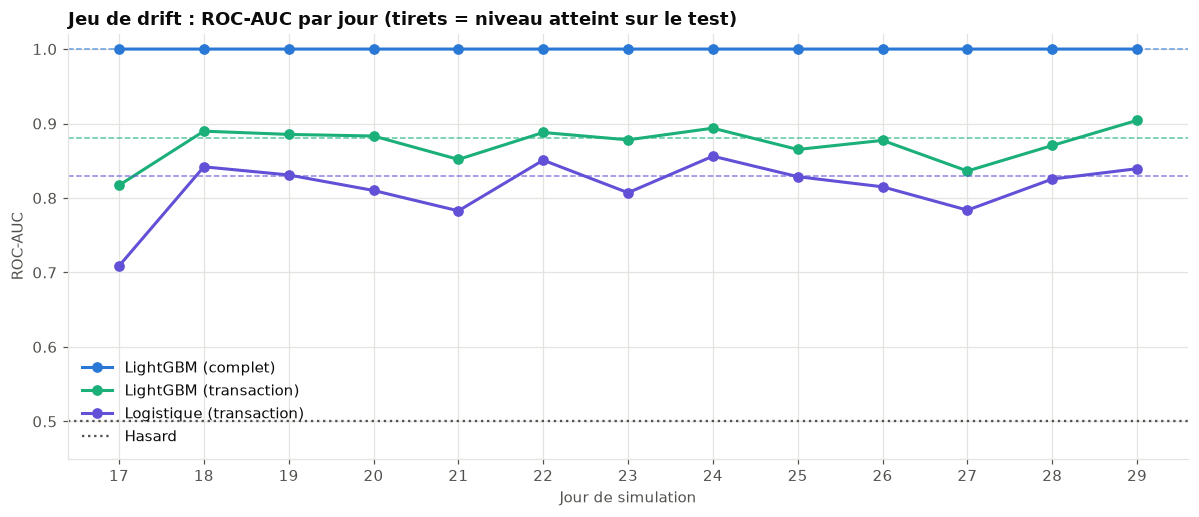

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.8))
plot_days = daily.dropna()  # jour 30 exclu : uniquement des fraudes
for color, name in zip(MODEL_COLORS, ["LightGBM (complet)", "LightGBM (transaction)", "Logistique (transaction)"]):
    ax.plot(plot_days.index, plot_days[name], marker="o", color=color, linewidth=2, label=name)
    ax.axhline(test.loc[name, "roc_auc"], color=color, linestyle="--", linewidth=1, alpha=0.7)
ax.axhline(0.5, color=TEXT_SECONDARY, linestyle=":", linewidth=1.5, label="Hasard")
ax.set_ylim(0.45, 1.02)
ax.set_xticks(plot_days.index)
ax.set_xlabel("Jour de simulation")
ax.set_ylabel("ROC-AUC")
ax.set_title("Jeu de drift : ROC-AUC par jour (tirets = niveau atteint sur le test)", loc="left")
ax.legend(loc="lower left")
fig.tight_layout()
save_fig(fig, "07_drift_par_jour")
plt.show()

**Lecture**
- **Jeu `complet` : robuste.** LightGBM conserve une ROC-AUC de 1,000 et une précision de 100 % sur les 14 jours de drift. Il détecte 99,5 % des fraudes et 99,2 % du montant. Les fraudes manquées sont surtout des transactions de **montant nul** et quelques transferts **plafonnés à 10 M** depuis des comptes plus riches. Les artefacts du simulateur sont **stables dans le temps** : ce qui rend le problème « facile » le reste.
- **Jeu `transaction` : légère érosion, mais robuste.** La ROC-AUC de LightGBM passe de 0,880 (test) à **0,873** (drift). Elle reste entre 0,82 et 0,90 chaque jour, toujours au-dessus de la logistique. Au seuil choisi sur la validation, le **rappel est stable** (54 % → 55 %) et 85 % du montant reste détecté.
- **La PR-AUC est trompeuse ici** : celle de LightGBM `transaction` « reste » à 0,42, mais avec un taux de fraude 14 fois plus élevé, un modèle aléatoire passerait de 0,002 à 0,023. De même, la précision monte de 5,5 % à 27 % sans que le modèle soit meilleur : il y a simplement plus de fraudes parmi les transactions. D'où le recours à la ROC-AUC pour juger la robustesse.
- **Point d'attention** : le jour 30 ne contient **que des fraudes** (141 TRANSFER + 141 CASH_OUT). C'est un artefact de fin de simulation, exclu de l'analyse par jour.
- ➡️ En production, le seuil devrait être **recalibré** quand la prévalence change fortement : avec 16 fois plus de fraudes, un seuil plus bas deviendrait rentable.

## 5. Conclusions

### Résultats finaux sur le test (jours 15-16, évalué une seule fois)

| Modèle | PR-AUC | Alertes | Fraudes détectées | Montant détecté | Coût total |
|---|---|---|---|---|---|
| Sans modèle | — | 0 | 0 % | 0 % | 968 M |
| Règle `isFlaggedFraud` | 0,003 | 1 | 0,2 % | 0,5 % | 963 M |
| Règle « compte vidé » | 0,972 | 554 | 97,2 % | 84,5 % | 150 M |
| Logistique (`transaction`) | 0,110 | 22 073 | 50,0 % | 75,2 % | 349 M |
| **LightGBM (`transaction`)** | **0,417** | 5 582 | 54,0 % | **88,2 %** | **141 M** |
| **LightGBM (`complet`)** | **1,000** | 569 | 99,8 % | **100 %** | **0** |

### Enseignements
1. **Le seuil compte autant que le modèle** : choisir le seuil par le coût métier plutôt qu'à 0,5 divise le coût par deux pour LightGBM `transaction` (validation). Le seuil optimal tolère une précision faible, car une fraude coûte bien plus cher qu'une vérification.
2. **La décision est robuste à l'hypothèse de coût** : sur une plage ×10 du coût d'une fausse alerte, le montant détecté reste entre 84 et 89 %.
3. **Les performances se généralisent au test** : aucune baisse par rapport à la validation.
4. **H6 est validée** : tous les modèles appris surpassent très significativement la règle `isFlaggedFraud`, qui est quasiment inopérante.
5. **Robustesse temporelle** : sur le jeu de drift (régime anormal, 14 fois plus de fraudes), le modèle `complet` reste parfait et le modèle `transaction` ne perd que 0,007 de ROC-AUC.

### Quel modèle retenir ?
- **Sur ces données simulées** : LightGBM `complet` (coût nul sur le test comme sur le drift).
- **Pour une mise en situation réelle** : LightGBM `transaction` est le résultat le plus **crédible**. Il ne s'appuie pas sur les artefacts de soldes du simulateur et intercepte tout de même 88 % du montant fraudé. Ses performances (PR-AUC ≈ 0,4) sont plus proches de ce qu'on observe sur des données réelles de fraude.

### Limites
- Données **simulées** : les performances du jeu `complet` ne se transposeraient pas à des données réelles.
- Coût métier **simplifié** : un coût fixe par fausse alerte, sans gêne client différenciée, sans capacité limitée d'analystes ni récupération partielle des fonds.
- Le test ne couvre que **2 jours** ; les intervalles bootstrap ignorent la dépendance temporelle.

### Suite (Phase 9)
**Explicabilité (SHAP)** : comprendre **pourquoi** les modèles décident, vérifier que LightGBM `complet` s'appuie bien sur les artefacts identifiés (compte vidé, soldes destinataires), relier les explications aux hypothèses H1-H5.